  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5        4   6  10  10  

[5 rows x 33 columns]
Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       '

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


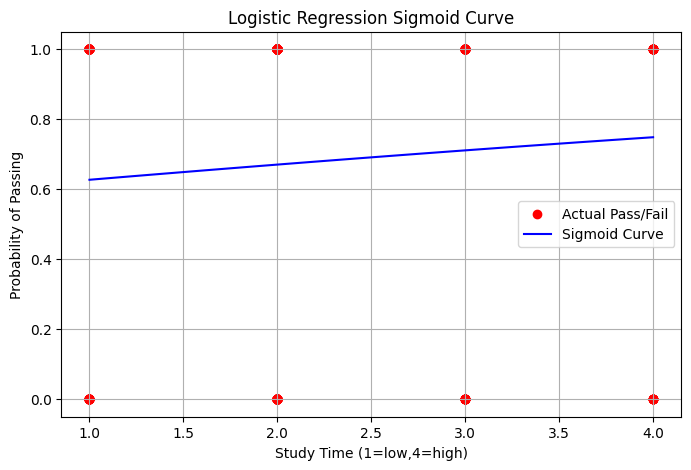

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

# Load dataset with correct separator
data = pd.read_csv("/content/student-mat.csv", sep=',')

# Check first few rows (optional)
print(data.head())
print(data.columns)  # now you should see separate columns like 'studytime', 'G1', 'G2', 'G3'

# Feature: studytime
X = data[['studytime']]

# Target: Pass = 1 if final grade G3 >= 10 else 0
data['pass'] = (data['G3'] >= 10).astype(int)
y = data['pass']

# Train Logistic Regression
model = LogisticRegression()
model.fit(X, y)

# Smooth values for sigmoid curve
X_test = np.linspace(X.values.min(), X.values.max(), 100).reshape(-1,1)
y_prob = model.predict_proba(X_test)[:,1]

# Plot
plt.figure(figsize=(8,5))
plt.scatter(X, y, color='red', label='Actual Pass/Fail')
plt.plot(X_test, y_prob, color='blue', label='Sigmoid Curve')
plt.xlabel("Study Time (1=low,4=high)")
plt.ylabel("Probability of Passing")
plt.title("Logistic Regression Sigmoid Curve")
plt.legend()
plt.grid(True)
plt.show()